# Recreate 4-point and 6-point EC fits

This notebook walks through a directory containing one text file per sample, extracts paired pore-water conductivity (`EC_water`) and bulk conductivity (`EC_bulk`), and fits the physical conductivity relation

\[
EC_{bulk} = \frac{1}{F} EC_{water} + \sigma_s,
\]

but **optimizes residuals in log10(EC_bulk) space**. This keeps `F` and `σs` physically interpretable; a straight regression of `log10(EC_bulk)` against `log10(EC_water)` would instead fit a power law whose slope/intercept are not formation factor and surface conductivity.

where `F = 1 / slope` is the formation factor and `σs = intercept` is the surface conductivity.

It compares two explicitly configurable fits:

- **4-point fit**: by default the first four measurements in each file, matching the four concentrations in the final report as closely as the raw files allow.
- **6-point fit**: by default all six measurements.
- **High-4 fit**: the four observations with the highest `EC_water` in each sample.
- **Exclude-2 fit**: all observations except the second measurement in the original file (normally 5 of 6 points).

The notebook also optionally reads the previously generated comparison workbook, joins the reported final-report and paper values, calculates residual differences, creates one log-log plot per sample with all four fits, and writes a combined CSV.

**Important:** The example file already shows that “first four” versus “all six” does not reproduce either published value exactly. The notebook therefore treats the point-selection rule as a testable configuration rather than assuming it is the full explanation.

In [1]:

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ---- USER SETTINGS ----
REVIL_DIR = Path(r"c:\Gitrepos\formationfactors\data\1-external\revil")
DATA_DIR = REVIL_DIR / "data"          # directory containing sample .txt files
FILE_GLOB = "*.txt"
REFERENCE_XLSX =REVIL_DIR / "Revil_results_consistency.xlsx"  # optional
OUTPUT_DIR = REVIL_DIR / "fit_check_output"
OUTPUT_DIR.mkdir(exist_ok=True)


# Point-selection rules. Alternatives: "lowest", "highest", or explicit targets.
FOUR_POINT_RULE = "lowest"
N_FOUR = 4
N_SIX = 6

# Optional target EC_water values. Set to None to use sorted point counts.
FOUR_TARGETS = None  # e.g. [0.031, 0.526, 1.037, 4.17]
SIX_TARGETS = None   # e.g. [0.031, 0.53, 1.15, 5.7, 14.7, 22.0]
TARGET_RTOL = 0.25   # maximum relative deviation for nearest-target matching

PLOT_EACH_SAMPLE = True
SHOW_PLOTS = True


In [2]:

def read_sample_file(path: Path) -> pd.DataFrame:
    """Read the first two numeric columns from a tab/space/comma/semicolon-delimited file."""
    rows = []
    for line in path.read_text(errors="replace").splitlines():
        tokens = [t for t in re.split(r"[\t,; ]+", line.strip()) if t]
        nums = []
        for t in tokens:
            try:
                nums.append(float(t.replace(",", ".")))
            except ValueError:
                pass
        if len(nums) >= 2:
            rows.append(nums[:2])
    if not rows:
        raise ValueError(f"No paired numeric columns found in {path.name}")
    df = pd.DataFrame(rows, columns=["EC_water", "EC_bulk"])
    return df.dropna().sort_values("EC_water").reset_index(drop=True)


def select_points(df, n=None, rule="lowest", targets=None, rtol=0.25):
    if targets is not None:
        chosen = []
        available = df.copy()
        for target in targets:
            if available.empty:
                break
            i = (available.EC_water - target).abs().idxmin()
            row = available.loc[i]
            rel = abs(row.EC_water - target) / max(abs(target), 1e-12)
            if rel > rtol:
                raise ValueError(f"No EC_water close enough to target {target}; nearest={row.EC_water}")
            chosen.append(row)
            available = available.drop(i)
        return pd.DataFrame(chosen).reset_index(drop=True)
    if n is None or len(df) < n:
        return df.copy()
    return (df.nsmallest(n, "EC_water") if rule == "lowest"
            else df.nlargest(n, "EC_water").sort_values("EC_water"))


def fit_logspace(df):
    """Fit EC_bulk = EC_water/F + SC by least squares in log10(EC_bulk).

    F and SC remain the physical model parameters. Positive bounds are used
    because log10 predictions require positive conductivity.
    """
    x = df.EC_water.to_numpy(float)
    y = df.EC_bulk.to_numpy(float)
    if np.any(x <= 0) or np.any(y <= 0):
        raise ValueError("Log-space fitting requires EC_water > 0 and EC_bulk > 0")

    # Linear-space fit supplies a stable initial guess only.
    slope0, sc0 = np.polyfit(x, y, 1)
    F0 = max(1.0 / max(slope0, 1e-12), 1e-6)
    sc0 = max(sc0, min(y) * 0.1, 1e-9)

    def residual(theta):
        logF, logSC = theta
        F, SC = np.exp(logF), np.exp(logSC)
        pred = x / F + SC
        return np.log10(pred) - np.log10(y)

    opt = least_squares(residual, np.log([F0, sc0]))
    F, SC = np.exp(opt.x)
    pred = x / F + SC
    log_res = np.log10(pred) - np.log10(y)
    ss_res = np.sum(log_res**2)
    logy = np.log10(y)
    ss_tot = np.sum((logy - logy.mean())**2)
    r2_log = np.nan if ss_tot == 0 else 1 - ss_res / ss_tot
    return {"n": len(df), "slope": 1/F, "F": F, "SC": SC,
            "R2_log": r2_log, "RMSE_log10": np.sqrt(np.mean(log_res**2)),
            "EC_min": x.min(), "EC_max": x.max(), "success": opt.success}


In [3]:

# Discover and inspect input files
files = sorted(DATA_DIR.glob(FILE_GLOB))
print(f"Found {len(files)} input files in {DATA_DIR.resolve()}")
if files:
    display(read_sample_file(files[0]))


Found 71 input files in C:\Gitrepos\formationfactors\data\1-external\revil\data


,EC_water,EC_bulk
0,0.03142,0.28105
1,0.52610,0.57666
2,1.03700,0.33541
3,4.16500,1.54540
4,9.78000,3.07550
5,14.04000,4.58210


In [4]:

# Optional reference values from the comparison workbook
reference = None
if REFERENCE_XLSX.exists():
    reference = pd.read_excel(REFERENCE_XLSX, sheet_name="Comparison")
    reference = reference.rename(columns={
        "Code Revil": "sample",
        "F final report": "F_reported_final",
        "SC final report": "SC_reported_final",
        "F paper": "F_reported_paper",
        "SC paper": "SC_reported_paper",
    })
    reference = reference[["sample", "F_reported_final", "SC_reported_final",
                           "F_reported_paper", "SC_reported_paper"]]
    display(reference.head())
else:
    print("Reference workbook not found; raw fits will still be produced.")


,sample,F_reported_final,SC_reported_final,F_reported_paper,SC_reported_paper
0,CW_0580586130,5.32,0.247,8.37,0.30
1,AE_0580586137,4.65,0.248,7.83,0.33
2,CT_0580586129,2.21,0.223,3.97,0.45
3,CS_0580586138,5.81,0.354,8.30,0.37
4,CV_0580586132,7.08,0.311,10.40,0.28


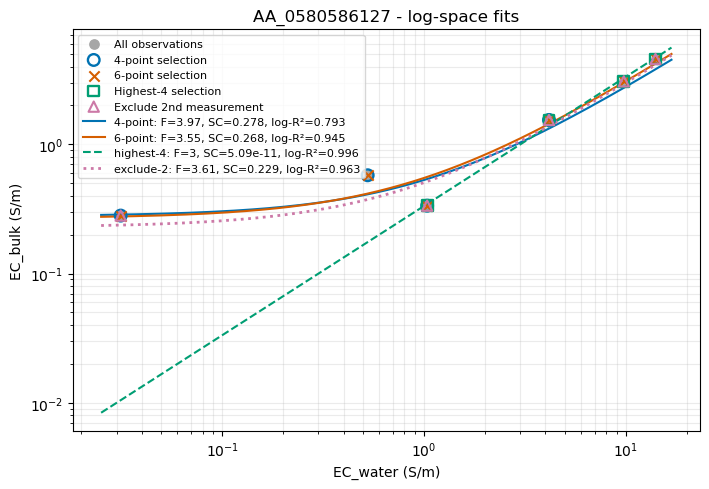

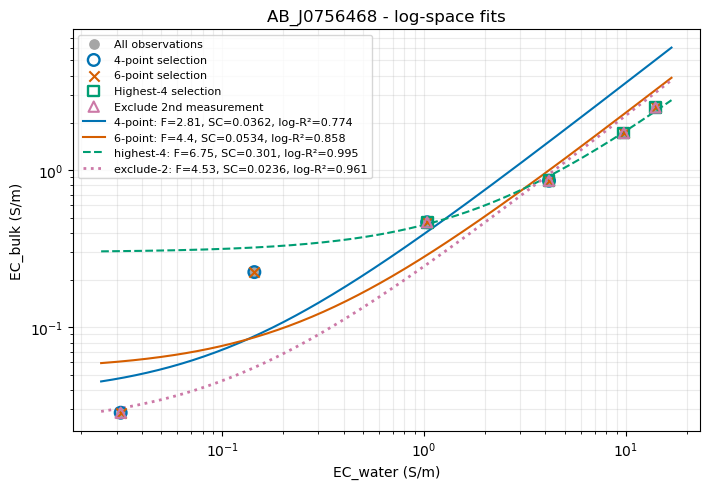

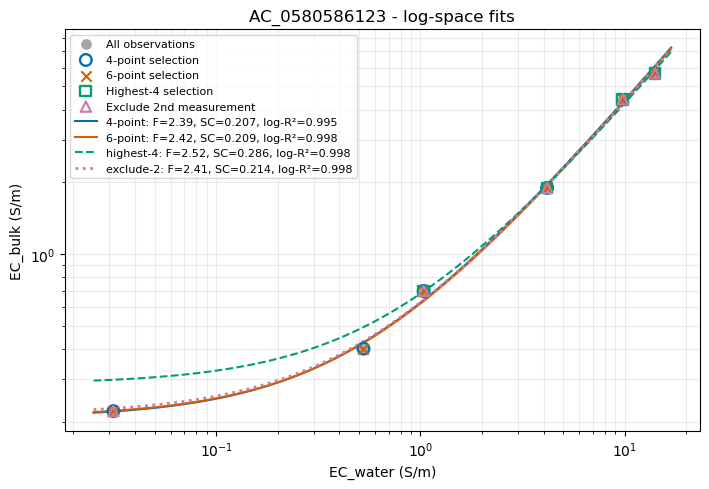

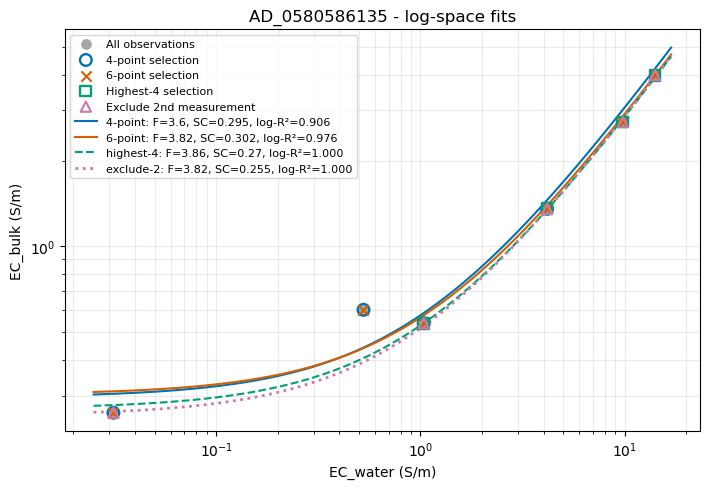

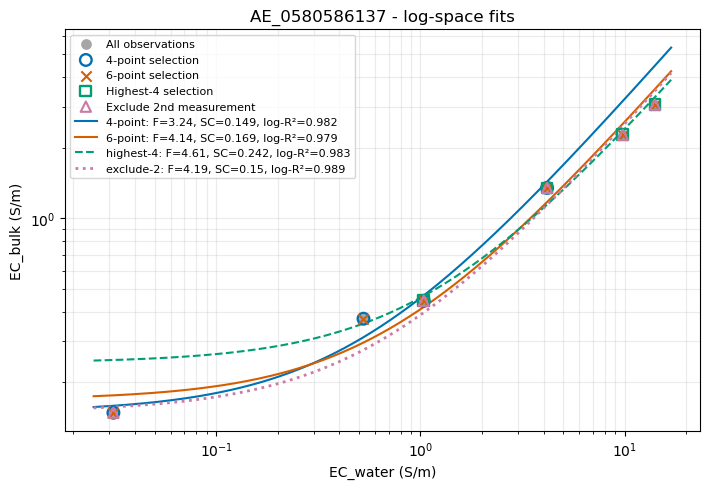

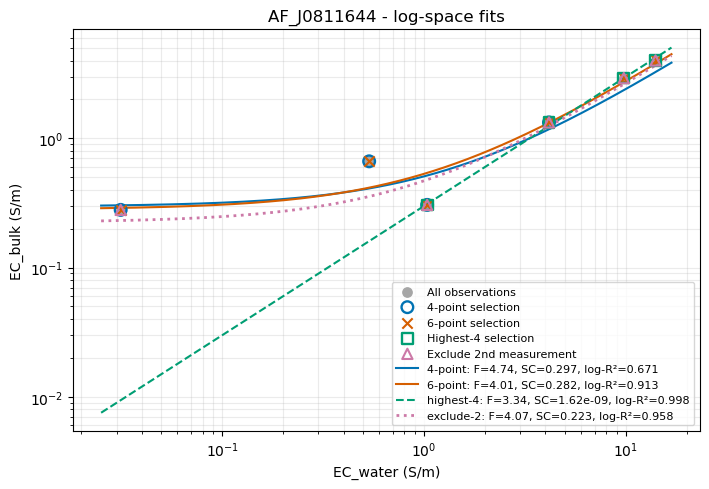

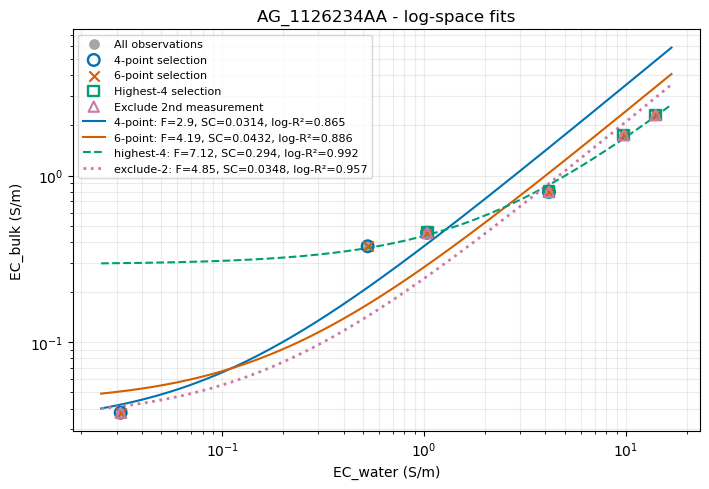

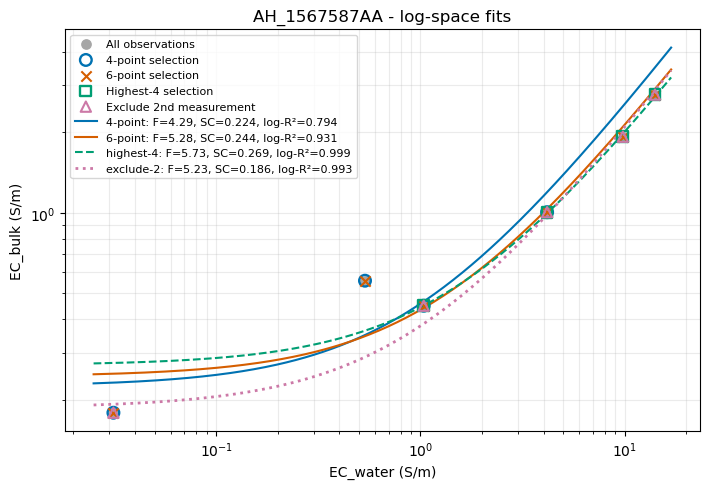

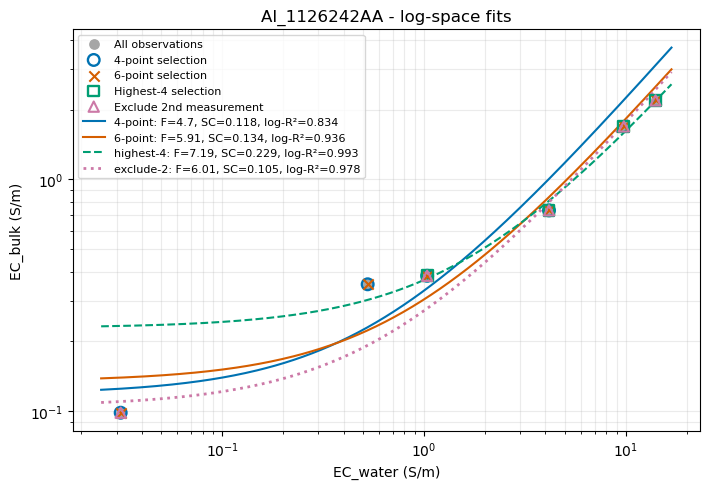

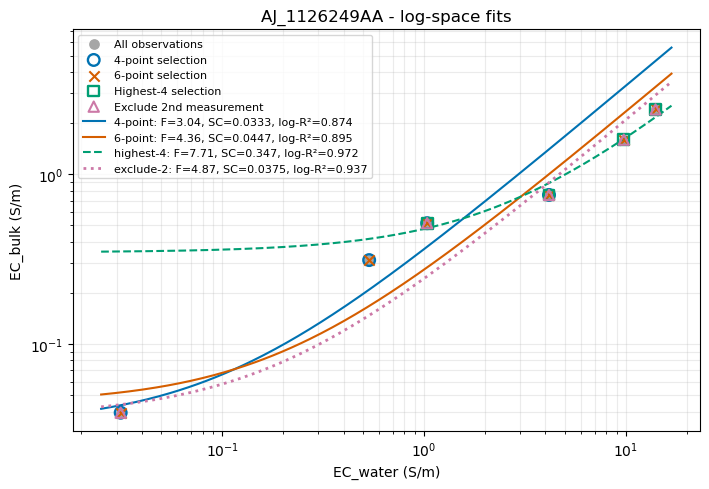

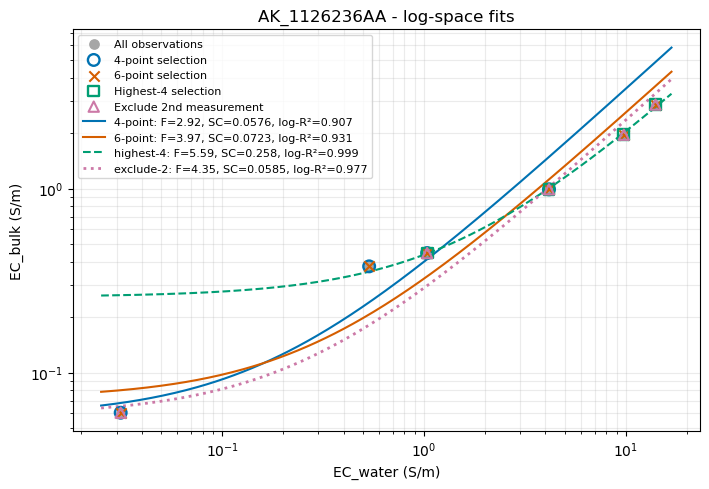

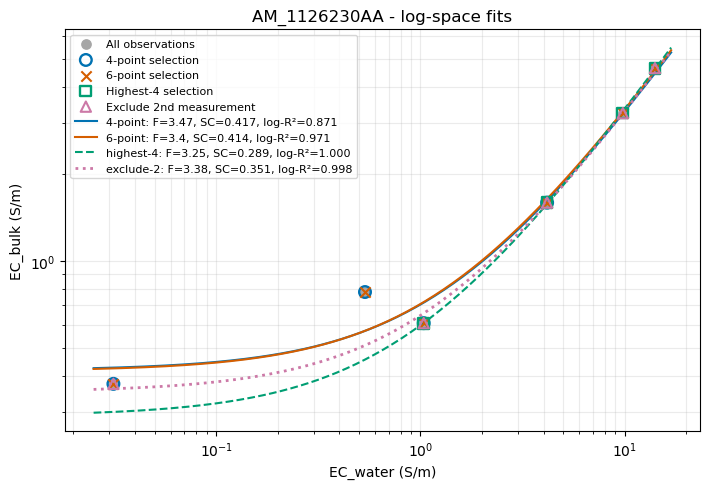

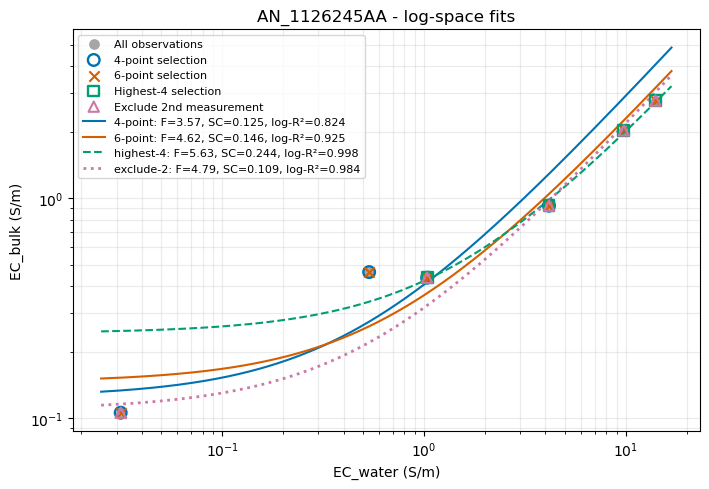

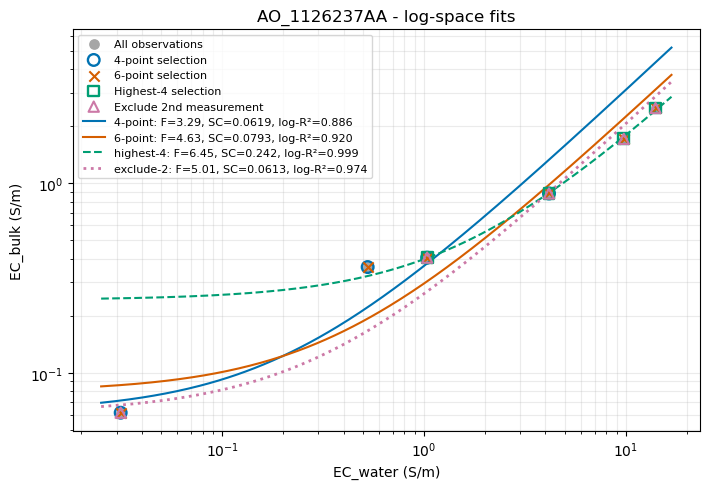

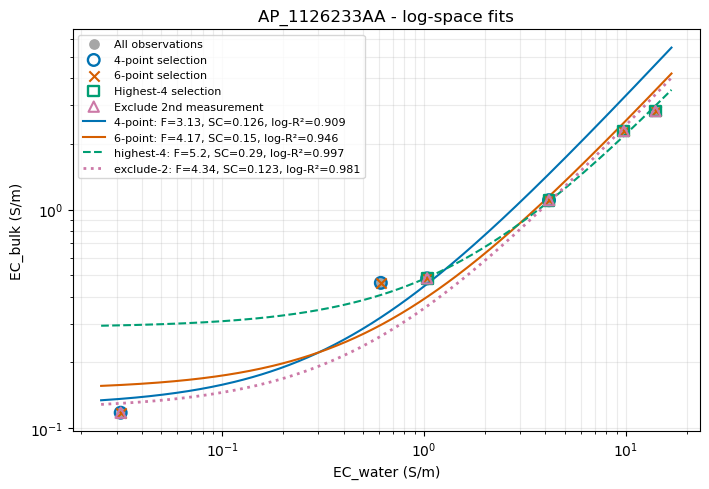

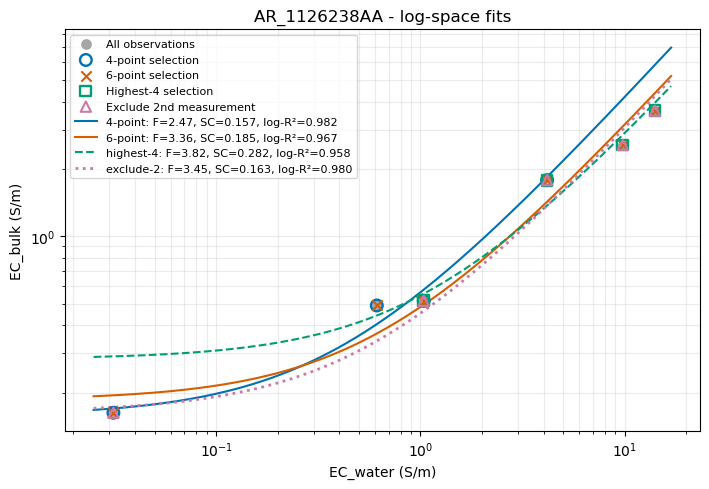

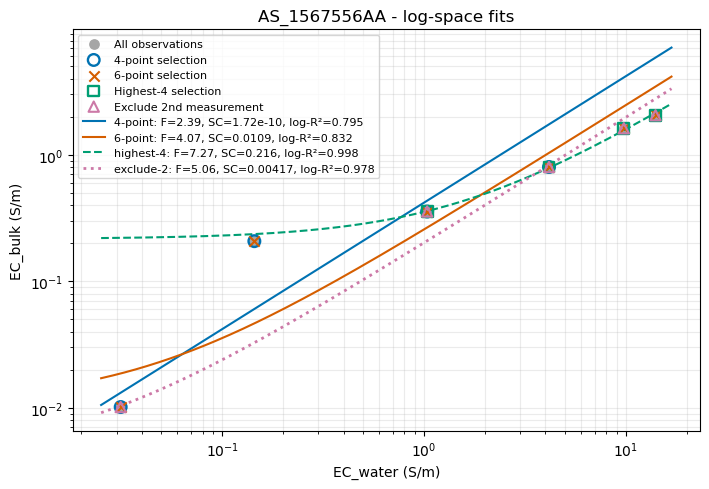

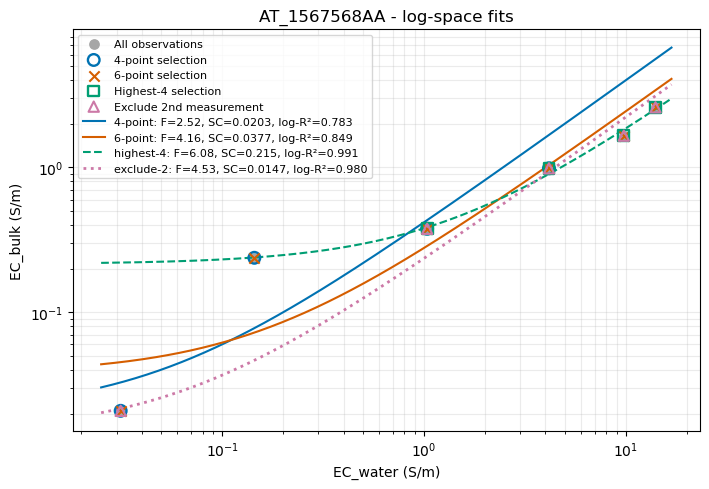

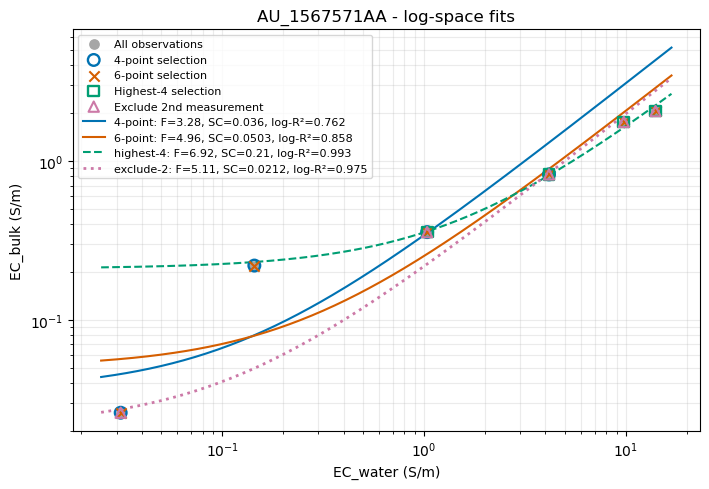

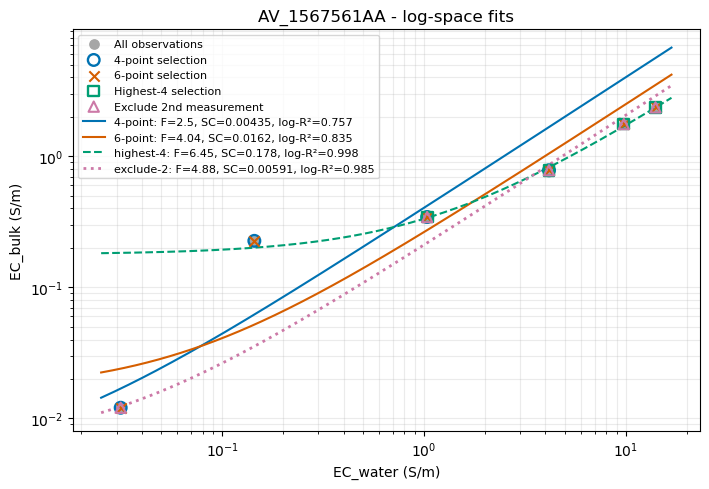

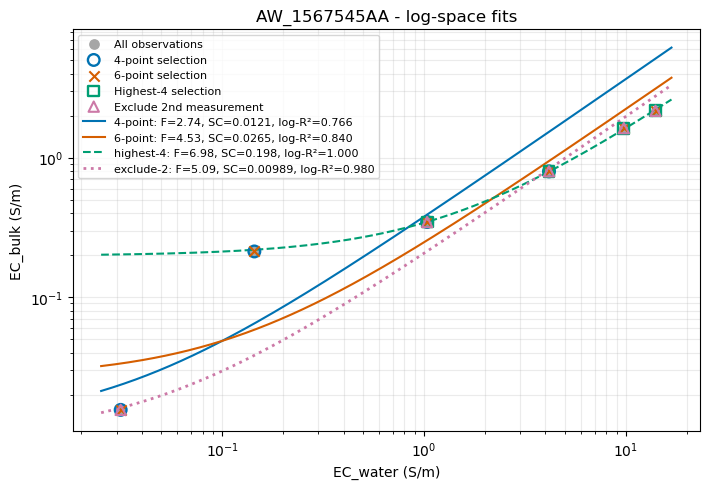

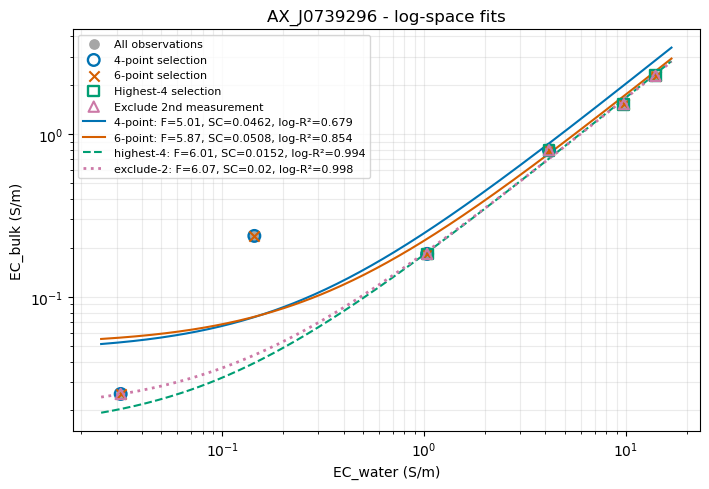

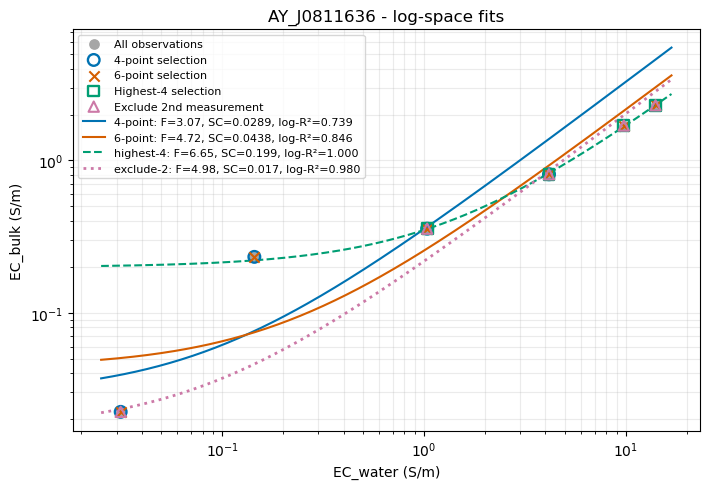

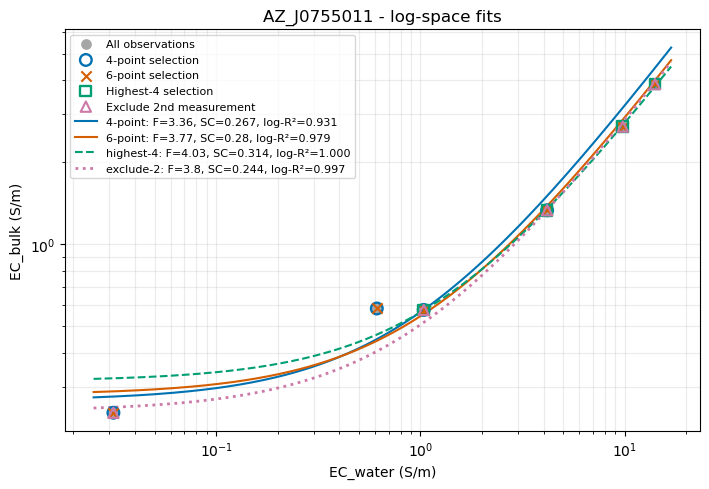

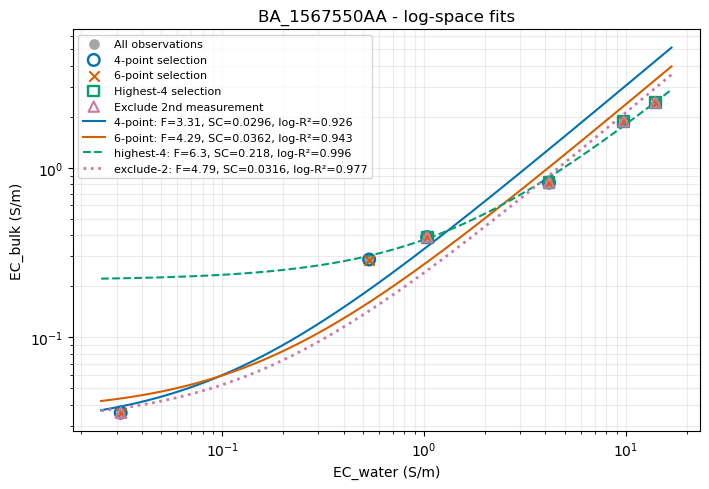

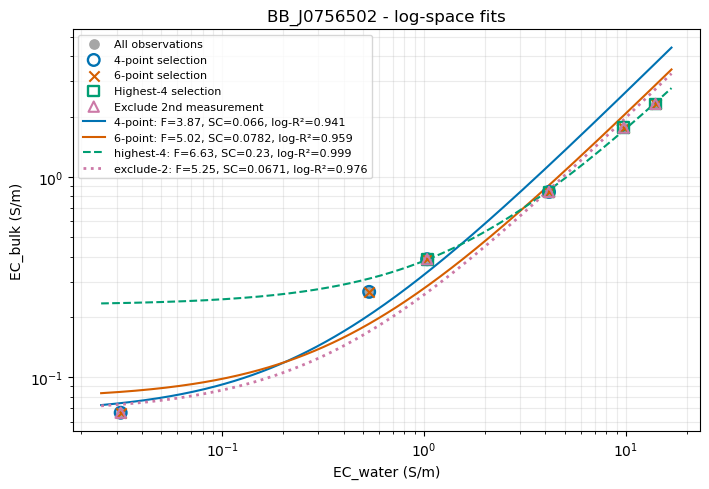

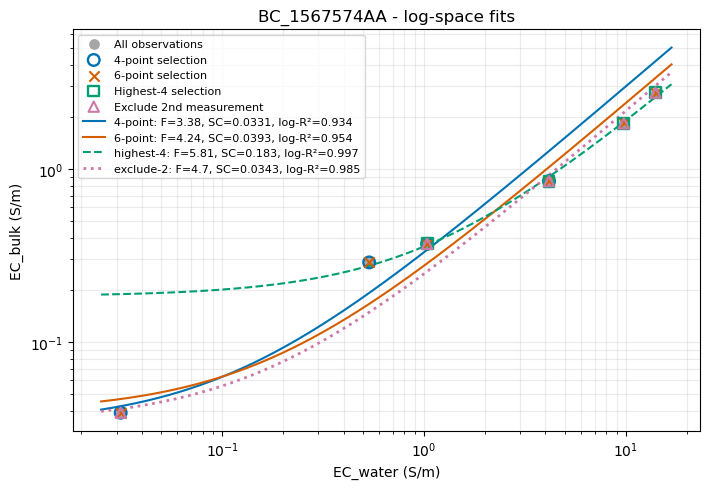

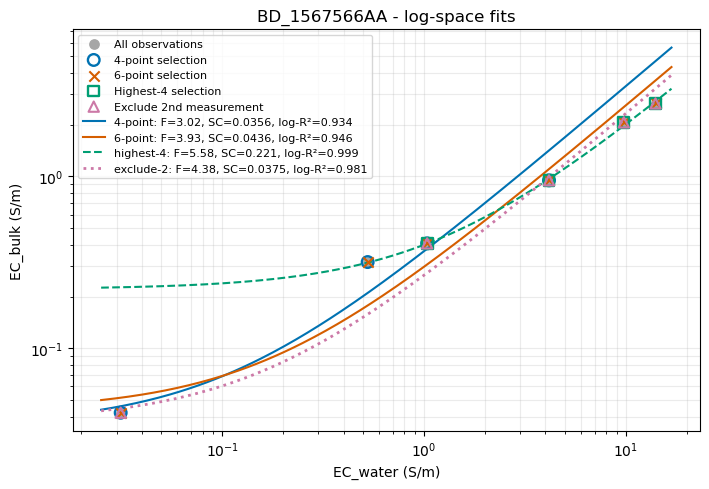

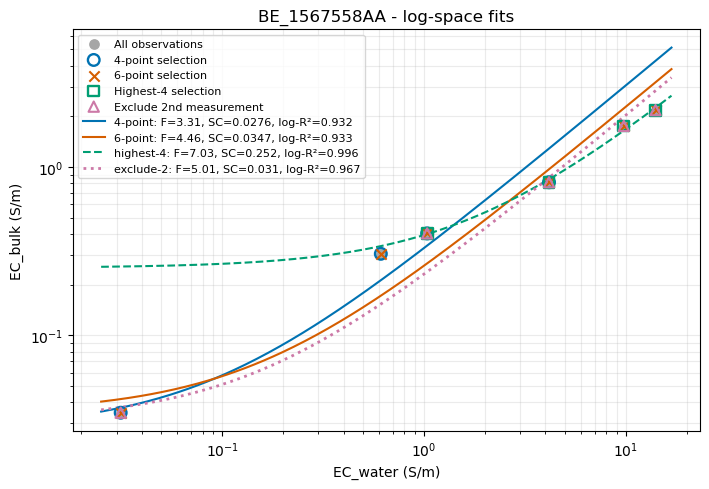

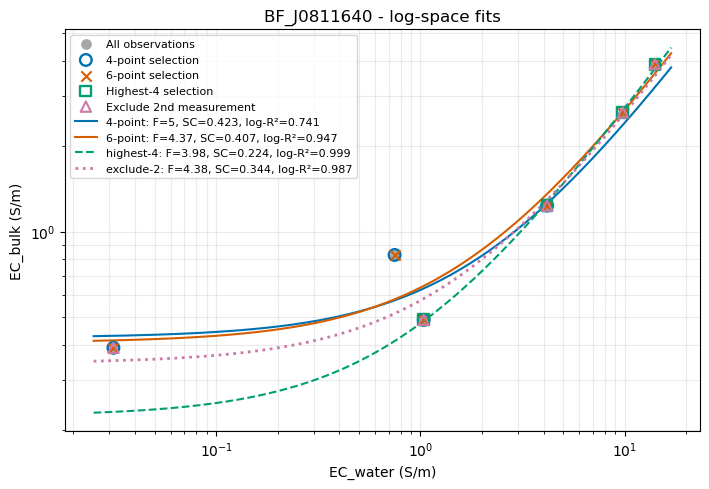

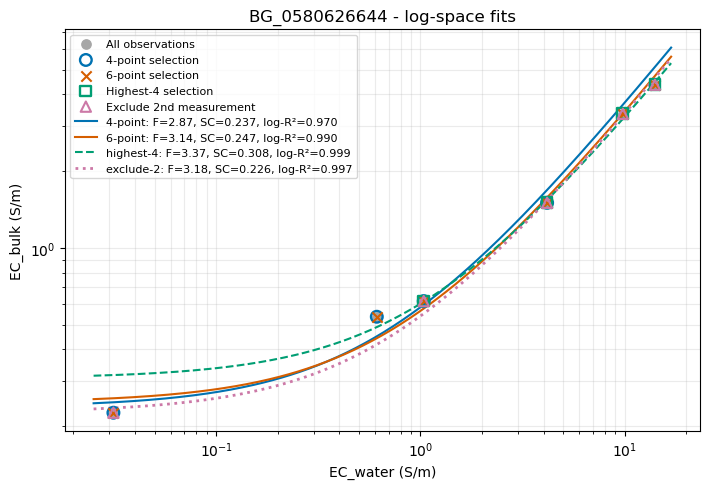

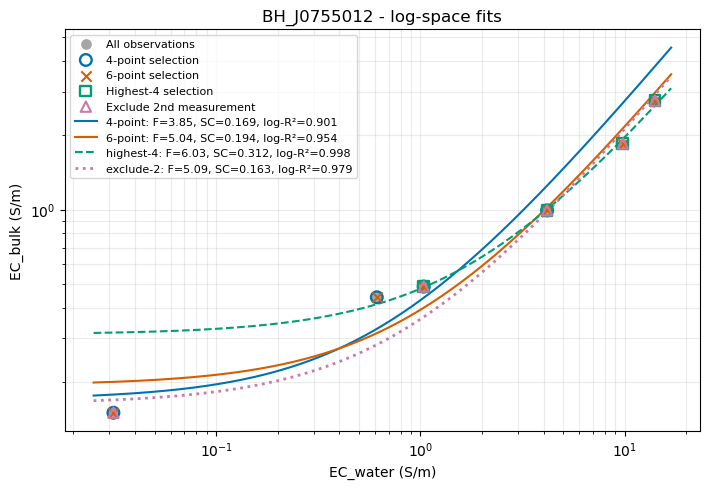

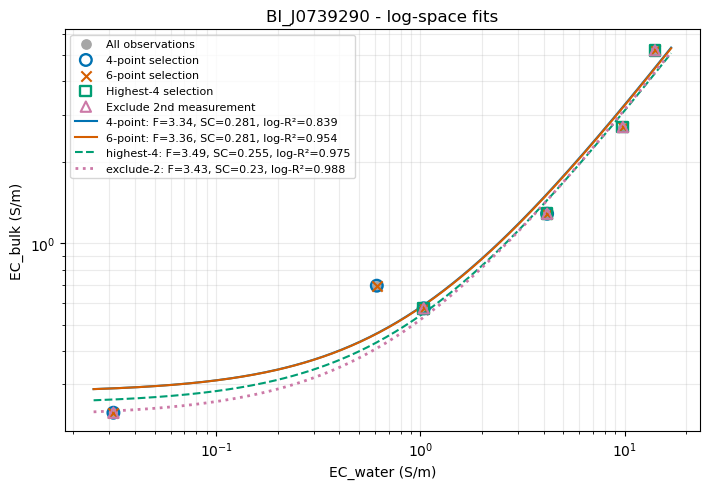

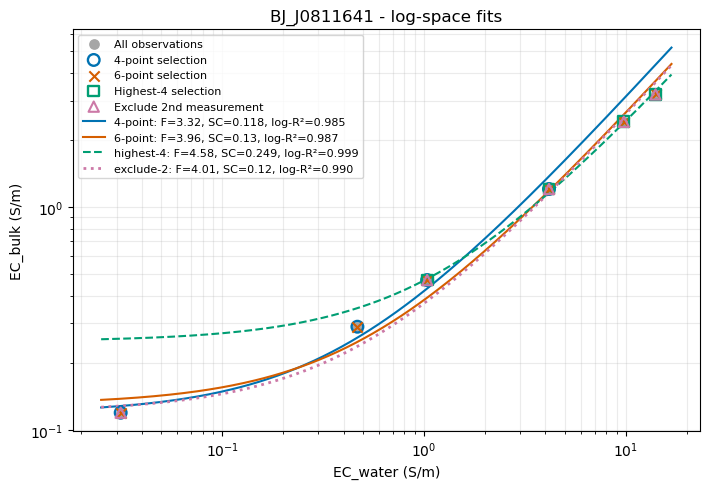

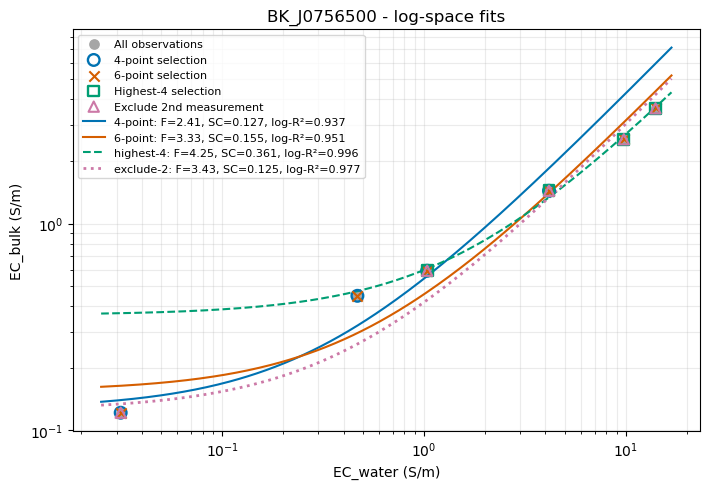

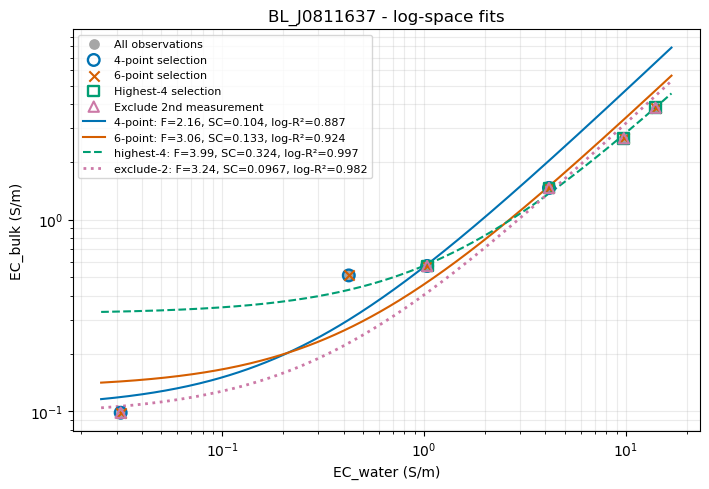

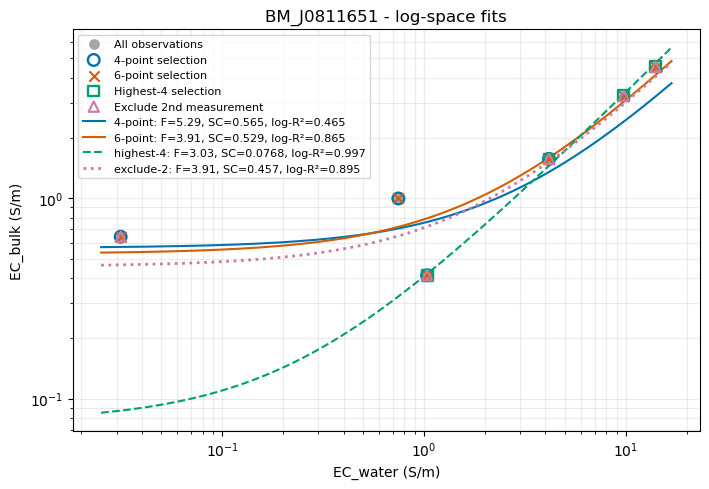

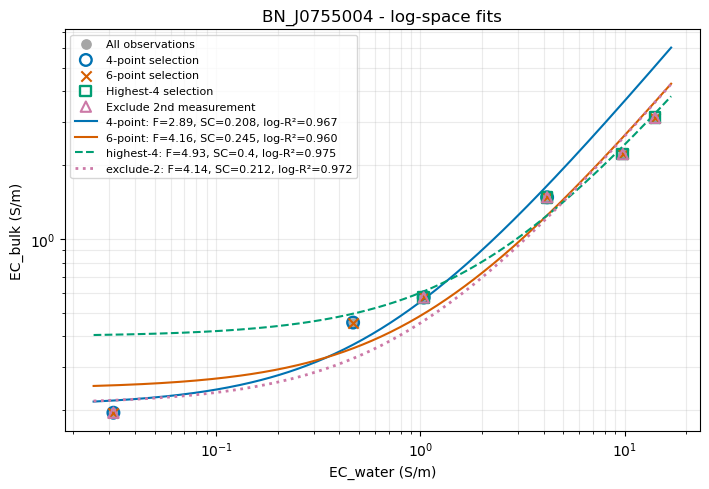

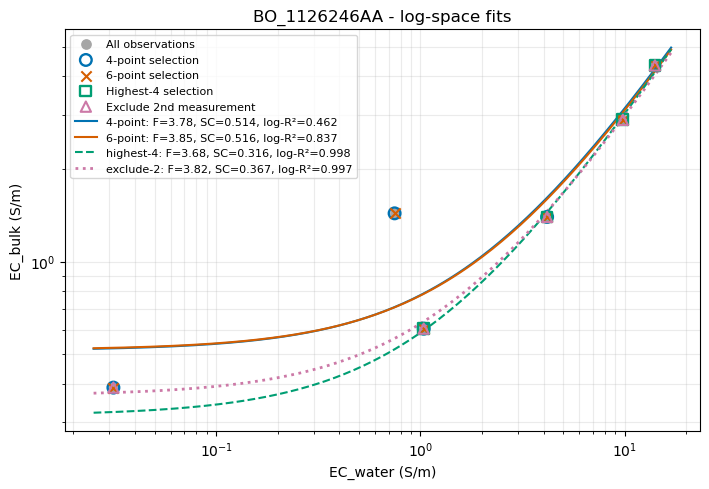

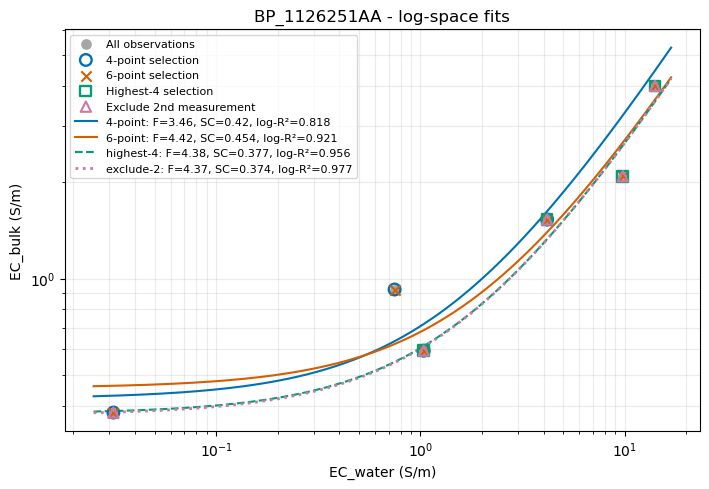

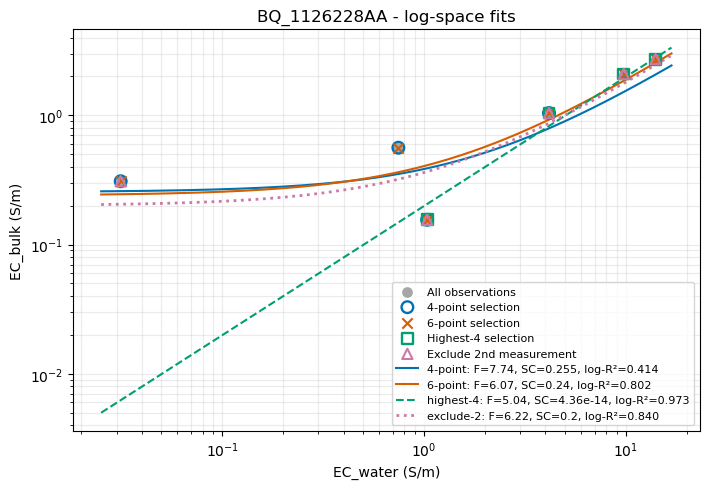

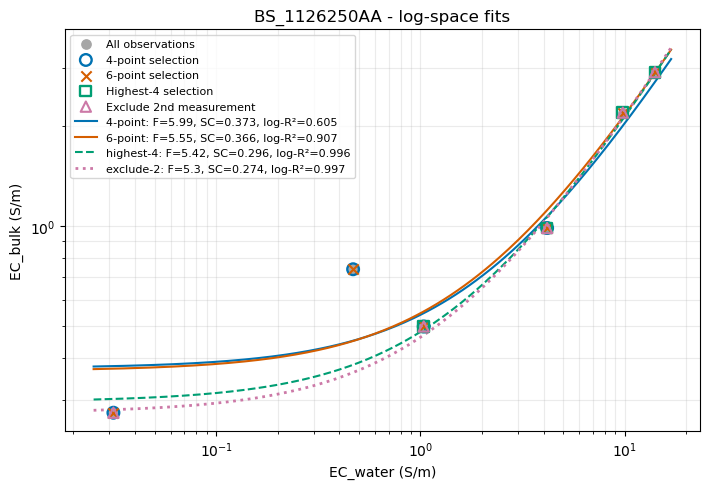

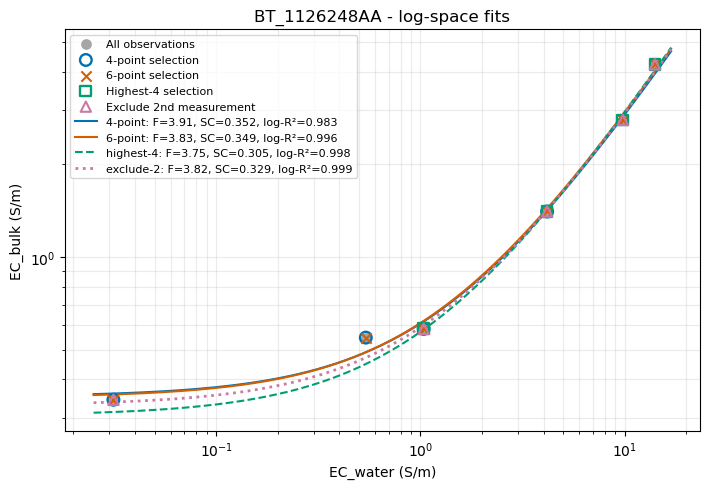

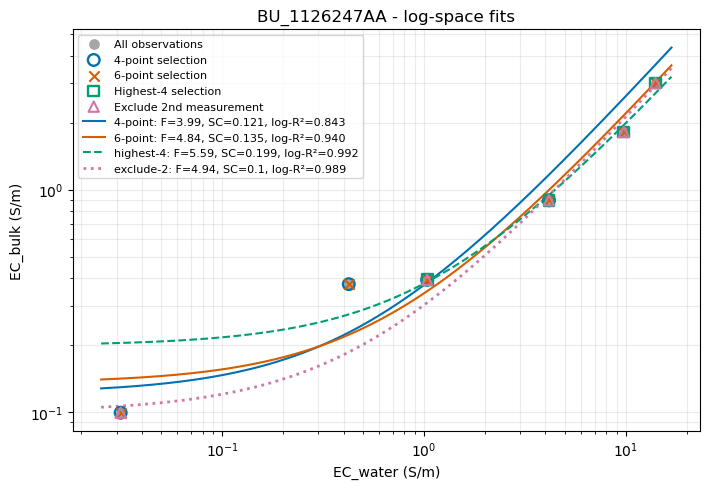

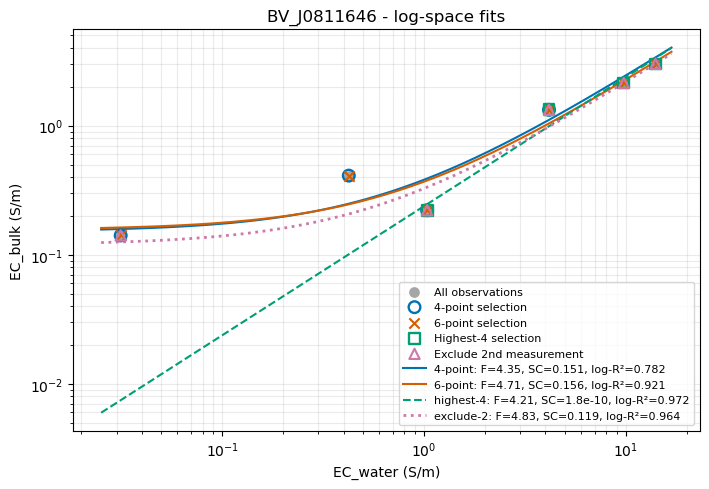

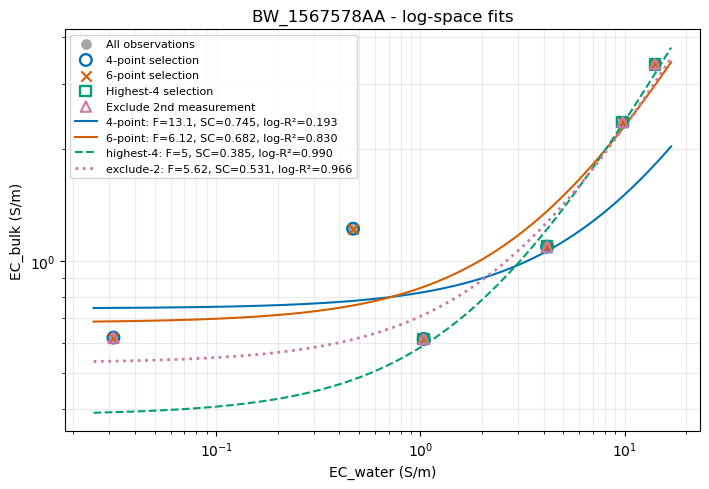

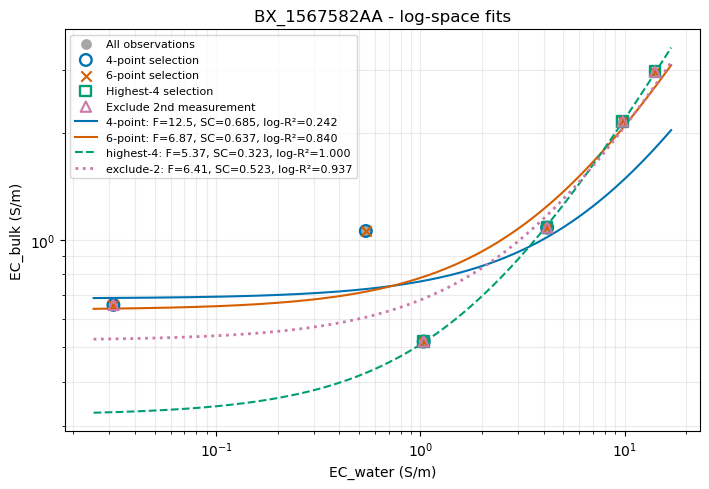

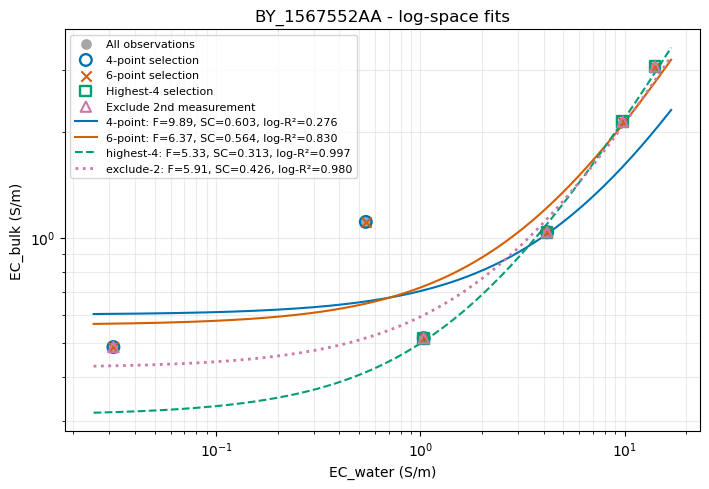

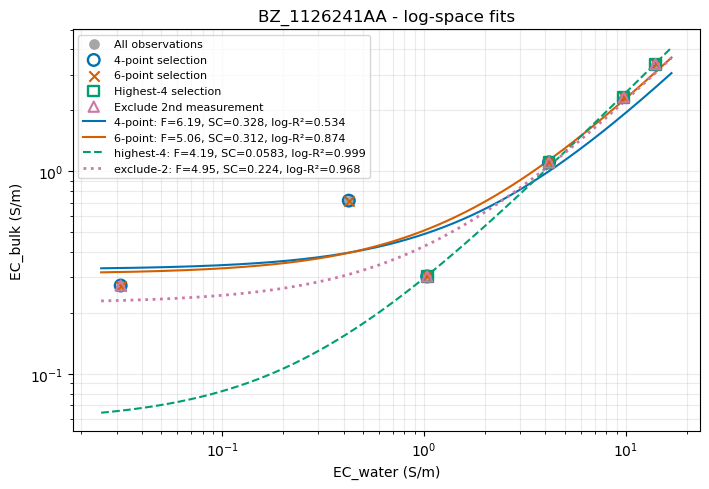

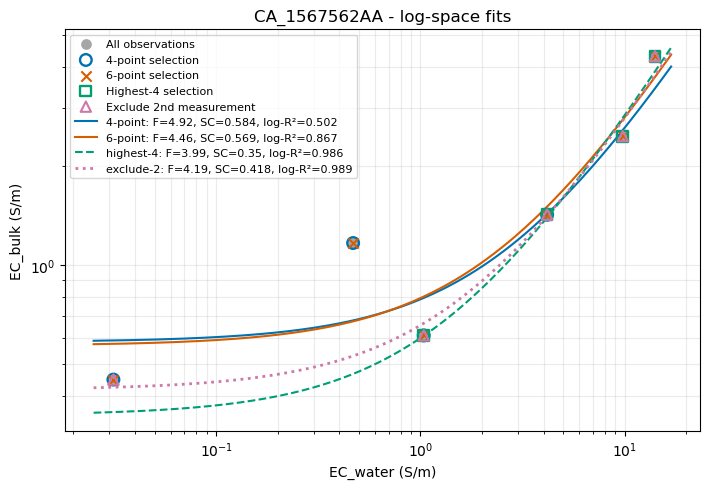

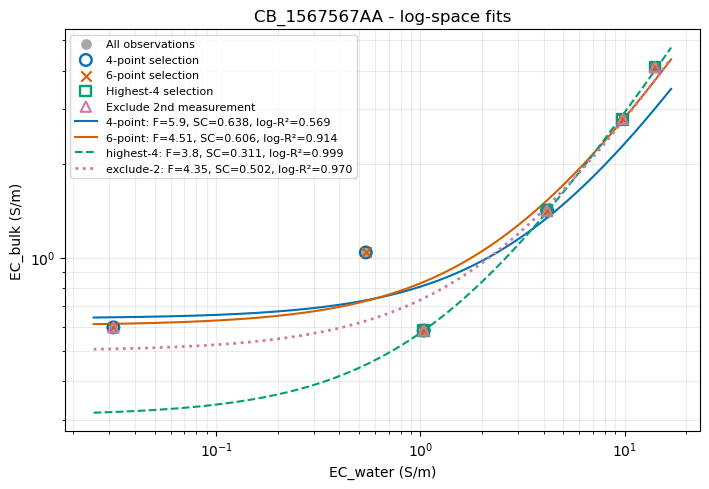

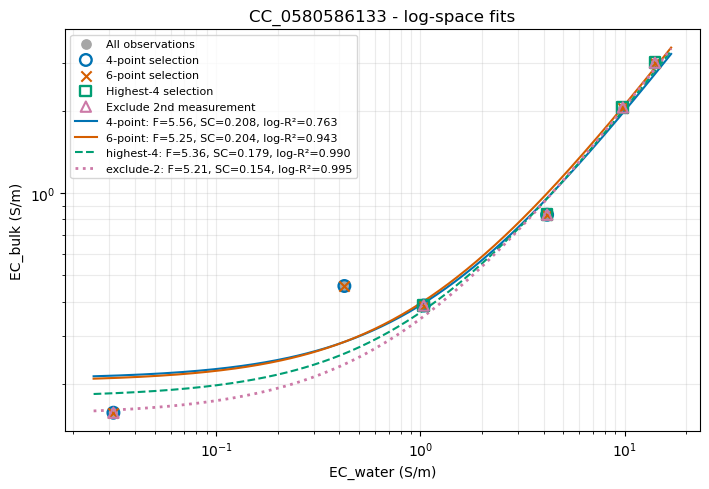

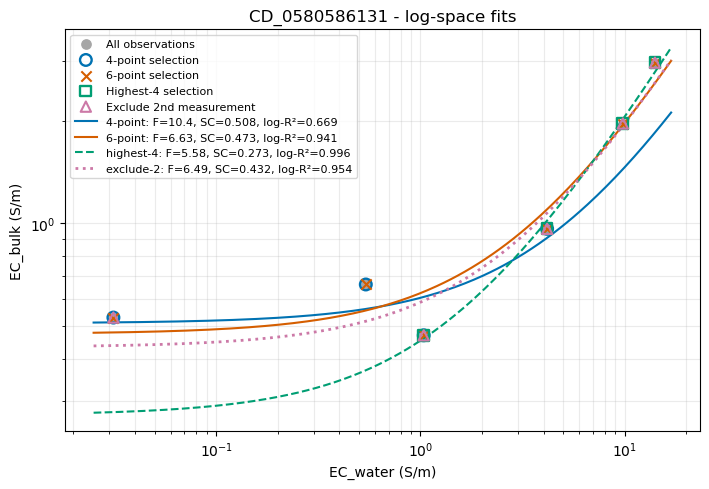

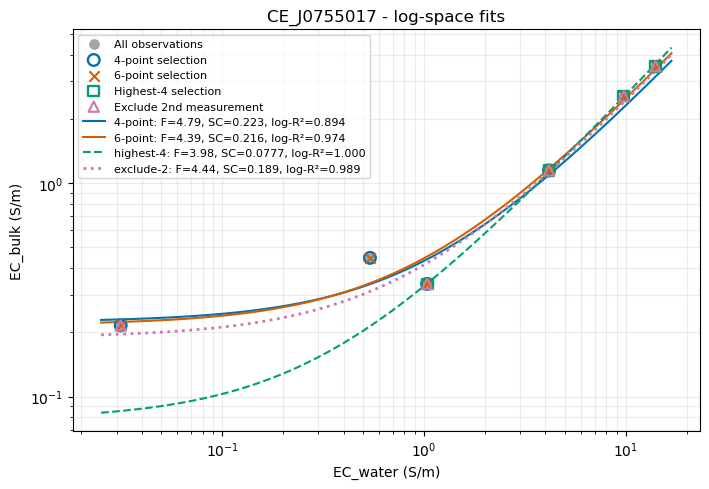

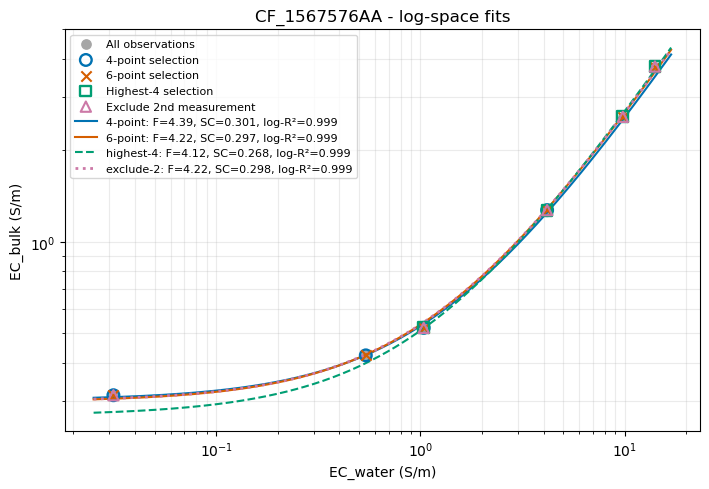

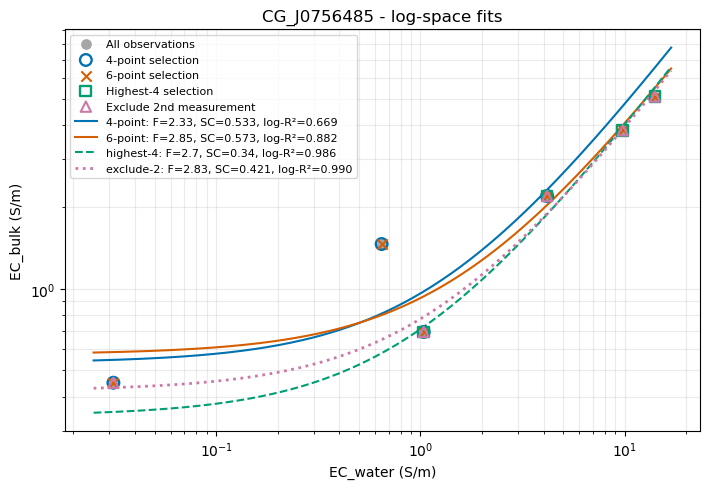

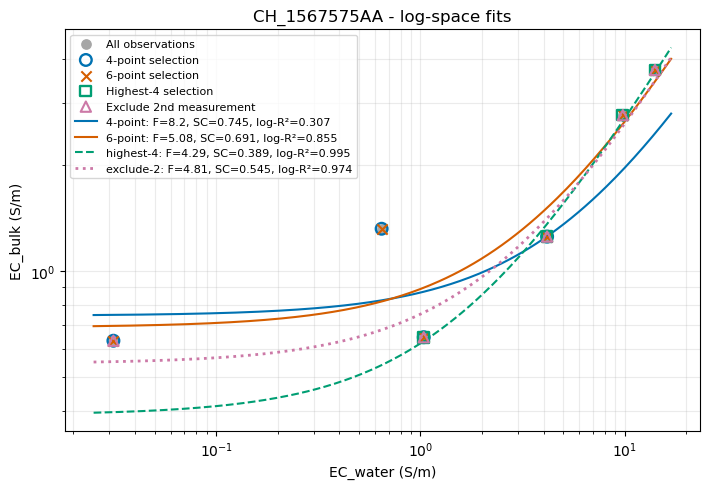

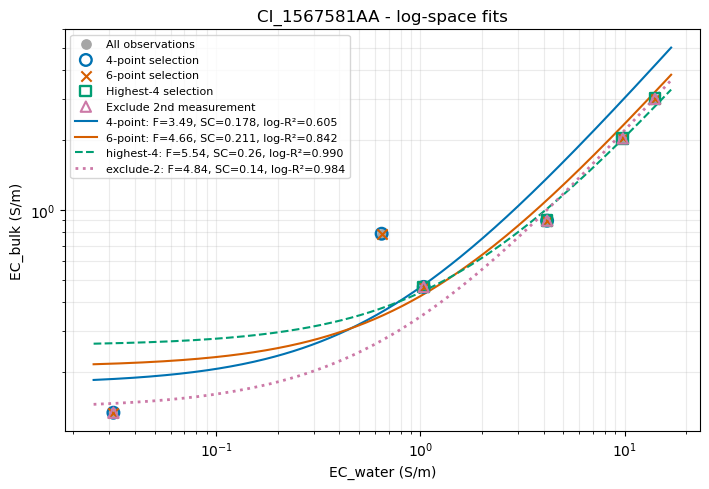

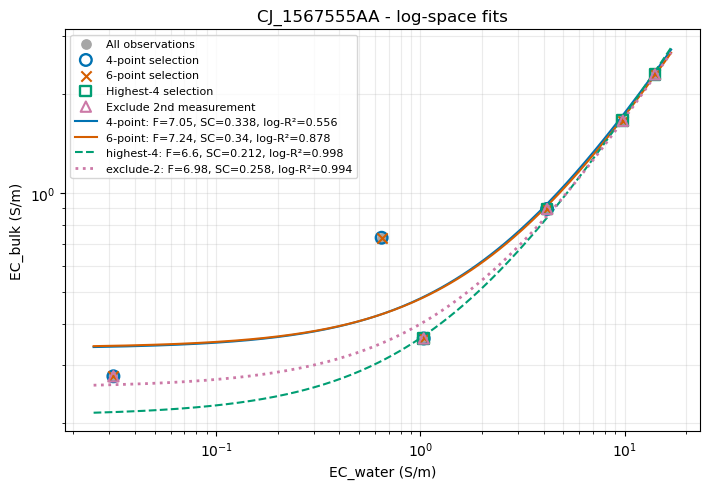

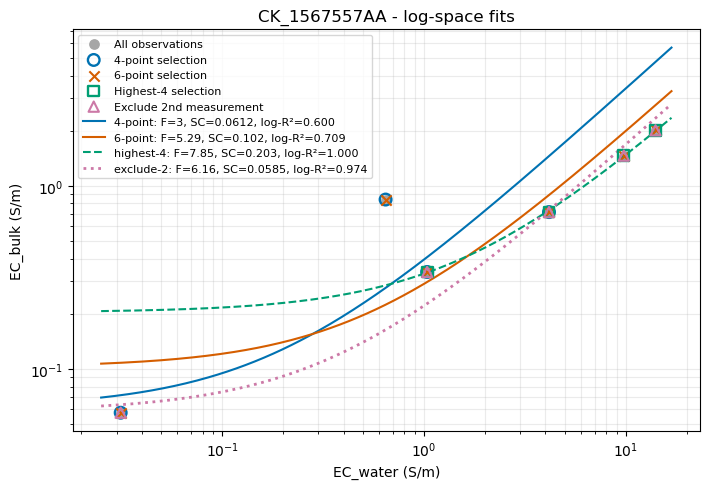

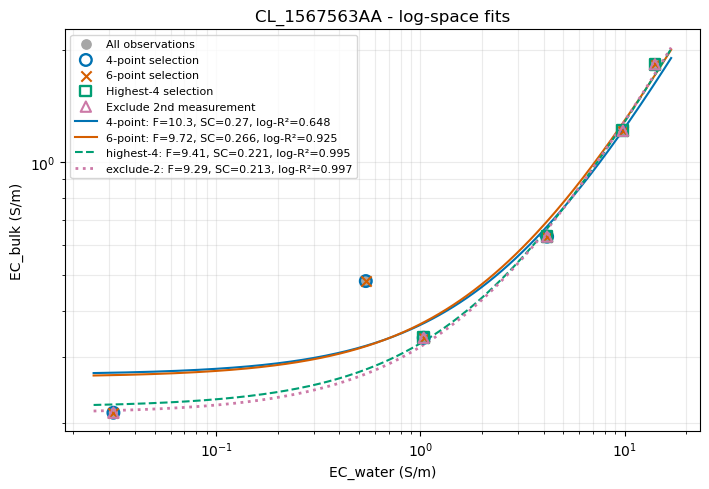

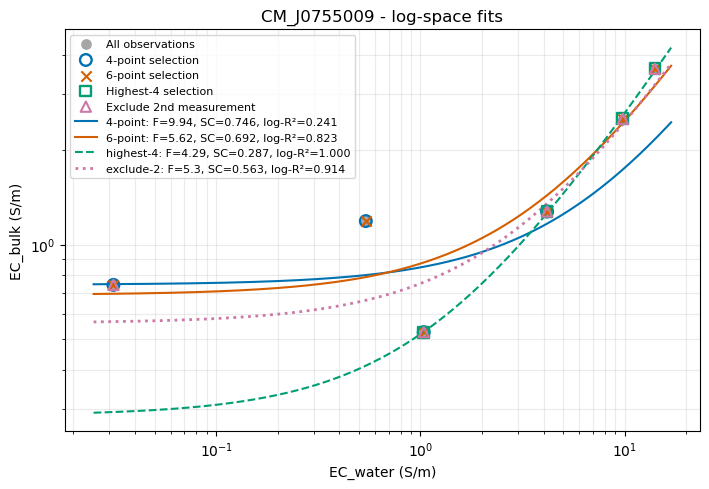

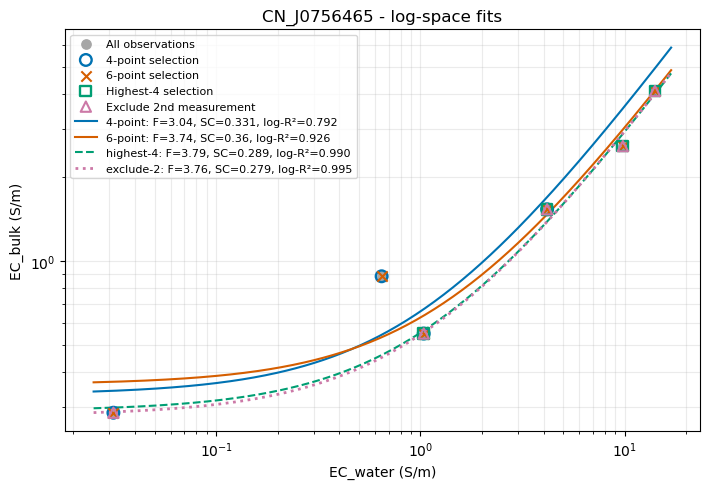

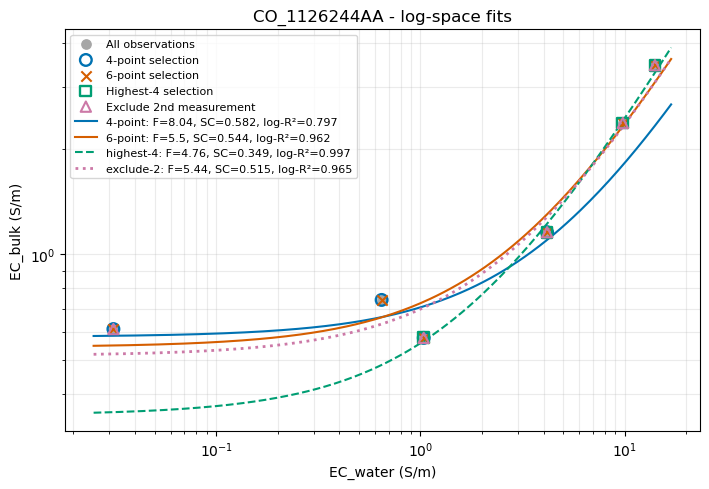

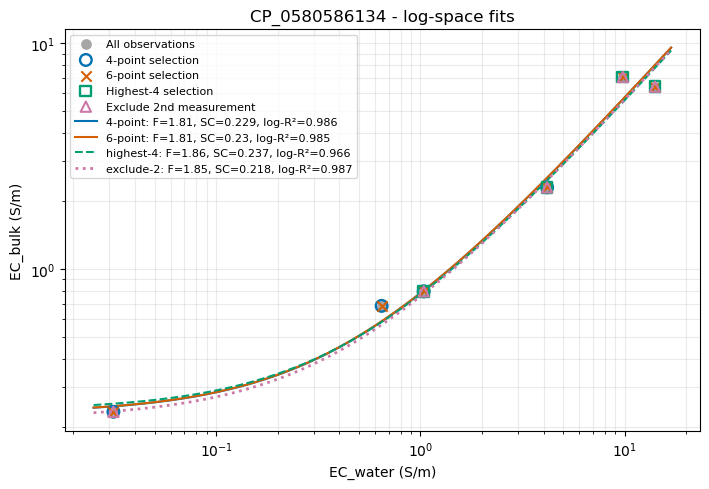

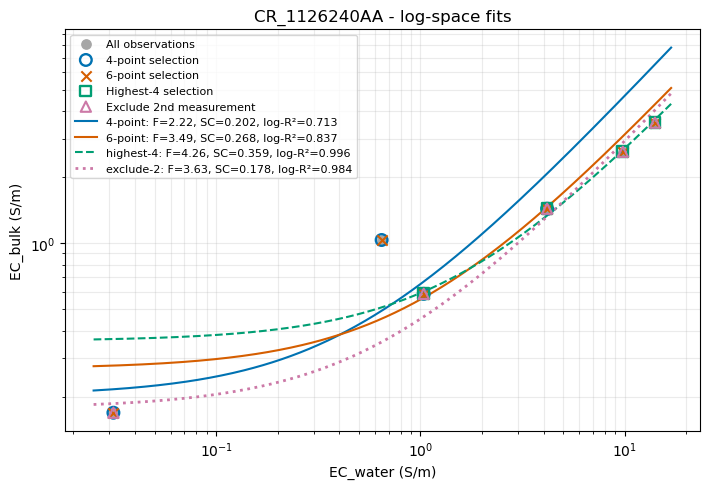

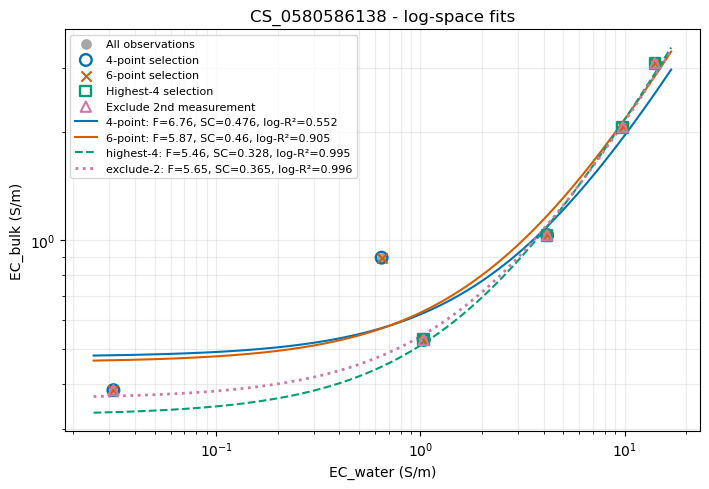

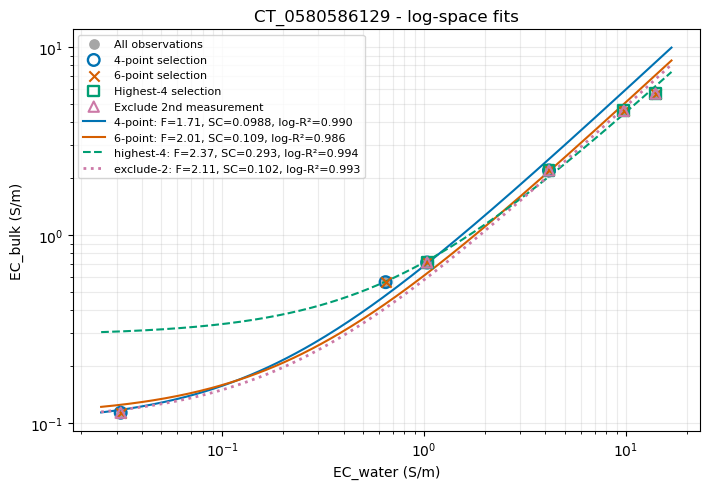

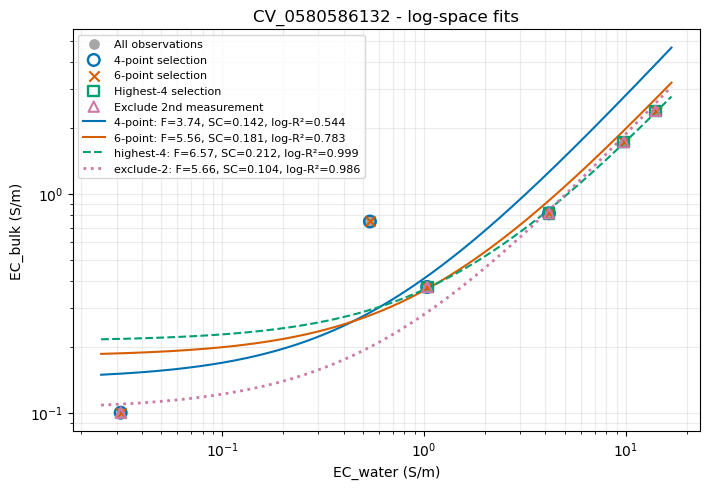

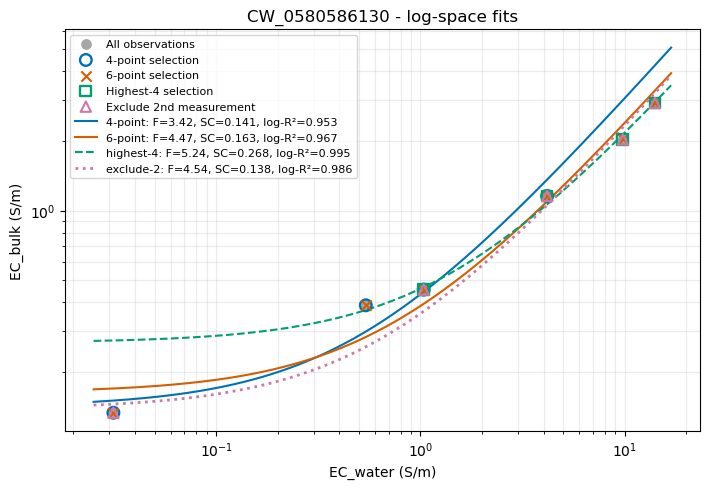

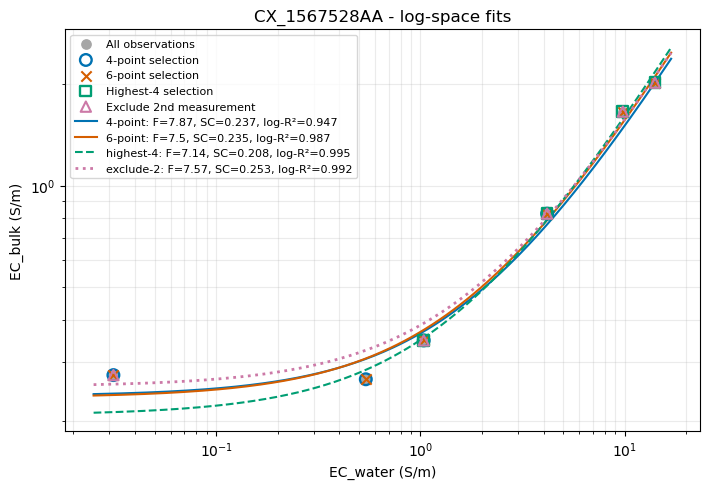

Processed 71 samples; 0 errors


,sample,file,n_raw,n_4pt,slope_4pt,F_4pt,SC_4pt,R2_log_4pt,RMSE_log10_4pt,EC_min_4pt,...,abs_rel_F_excl2_vs_final,abs_rel_SC_excl2_vs_final,dF_high4_vs_paper,dSC_high4_vs_paper,abs_rel_F_high4_vs_paper,abs_rel_SC_high4_vs_paper,dF_excl2_vs_paper,dSC_excl2_vs_paper,abs_rel_F_excl2_vs_paper,abs_rel_SC_excl2_vs_paper
0,AA_0580586127,AA_0580586127.txt,6,4,0.251688,3.973165,0.278174,0.793345,0.131074,0.03142,...,0.042303,0.134310,-2.298242,-0.400000,0.433631,1.000000,-1.693633,-0.171458,0.319553,0.428645
1,AB_J0756468,AB_J0756468.txt,6,4,0.356411,2.805746,0.036246,0.773798,0.264949,0.03142,...,0.313767,0.904946,0.454398,0.070775,0.072127,0.307719,-1.770859,-0.206427,0.281089,0.897507
2,AC_0580586123,AC_0580586123.txt,6,4,0.418955,2.386893,0.207199,0.994919,0.024425,0.03142,...,0.033805,0.102739,-1.483529,-0.083626,0.370882,0.226017,-1.591235,-0.156069,0.397809,0.421807
3,AD_0580586135,AD_0580586135.txt,6,4,0.278015,3.596925,0.295463,0.905949,0.077739,0.03142,...,0.063834,0.237632,-2.306516,-0.120462,0.373828,0.308876,-2.350443,-0.134607,0.380947,0.345145
4,AE_0580586137,AE_0580586137.txt,6,4,0.308683,3.239567,0.149344,0.982093,0.045563,0.03142,...,0.098350,0.396149,-3.223626,-0.087570,0.411702,0.265365,-3.637329,-0.180245,0.464537,0.546197


In [5]:

results = []
errors = []
for path in files:
    sample = path.stem
    try:
        raw = read_sample_file(path)
        p4 = select_points(raw, n=N_FOUR, rule=FOUR_POINT_RULE,
                           targets=FOUR_TARGETS, rtol=TARGET_RTOL)
        p6 = select_points(raw, n=N_SIX, rule="lowest",
                           targets=SIX_TARGETS, rtol=TARGET_RTOL)
        ph4 = select_points(raw, n=4, rule="highest")
        # Exclude the second measurement by ORIGINAL FILE ORDER, not salinity-sorted order.
        raw_original = read_sample_file(path)
        # read_sample_file sorts by EC_water, so re-read while preserving row order for this diagnostic.
        pairs = []
        for line in path.read_text(errors="replace").splitlines():
            toks = [t for t in re.split(r"[\t,; ]+", line.strip()) if t]
            nums = []
            for t in toks:
                try: nums.append(float(t.replace(",", ".")))
                except ValueError: pass
            if len(nums) >= 2: pairs.append(nums[:2])
        raw_file_order = pd.DataFrame(pairs, columns=["EC_water", "EC_bulk"])
        pex2 = raw_file_order.drop(raw_file_order.index[1]).reset_index(drop=True) if len(raw_file_order) >= 2 else raw_file_order.copy()
        f4, f6, fh4, fex2 = fit_logspace(p4), fit_logspace(p6), fit_logspace(ph4), fit_logspace(pex2)
        row = {"sample": sample, "file": path.name, "n_raw": len(raw)}
        row.update({f"{k}_4pt": v for k, v in f4.items()})
        row.update({f"{k}_6pt": v for k, v in f6.items()})
        row.update({f"{k}_high4": v for k, v in fh4.items()})
        row.update({f"{k}_excl2": v for k, v in fex2.items()})
        results.append(row)

        if PLOT_EACH_SAMPLE:
            fig, ax = plt.subplots(figsize=(7.2, 5.0))
            ax.scatter(raw.EC_water, raw.EC_bulk, c="0.65", s=45, label="All observations", zorder=2)
            ax.scatter(p4.EC_water, p4.EC_bulk, marker="o", s=70, facecolors="none",
                       edgecolors="#0072B2", linewidths=1.7, label="4-point selection", zorder=3)
            ax.scatter(p6.EC_water, p6.EC_bulk, marker="x", s=55, color="#D55E00",
                       label="6-point selection", zorder=4)
            ax.scatter(ph4.EC_water, ph4.EC_bulk, marker="s", s=60, facecolors="none",
                       edgecolors="#009E73", linewidths=1.7, label="Highest-4 selection", zorder=5)
            ax.scatter(pex2.EC_water, pex2.EC_bulk, marker="^", s=55, facecolors="none",
                       edgecolors="#CC79A7", linewidths=1.5, label="Exclude 2nd measurement", zorder=6)
            xx = np.geomspace(raw.EC_water.min()*0.8, raw.EC_water.max()*1.2, 250)
            ax.plot(xx, f4["slope"]*xx + f4["SC"], color="#0072B2",
                    label=f'4-point: F={f4["F"]:.3g}, SC={f4["SC"]:.3g}, log-R²={f4["R2_log"]:.3f}')
            ax.plot(xx, f6["slope"]*xx + f6["SC"], color="#D55E00",
                    label=f'6-point: F={f6["F"]:.3g}, SC={f6["SC"]:.3g}, log-R²={f6["R2_log"]:.3f}')
            ax.plot(xx, fh4["slope"]*xx + fh4["SC"], color="#009E73", linestyle="--",
                    label=f'highest-4: F={fh4["F"]:.3g}, SC={fh4["SC"]:.3g}, log-R²={fh4["R2_log"]:.3f}')
            ax.plot(xx, fex2["slope"]*xx + fex2["SC"], color="#CC79A7", linestyle=":", linewidth=2,
                    label=f'exclude-2: F={fex2["F"]:.3g}, SC={fex2["SC"]:.3g}, log-R²={fex2["R2_log"]:.3f}')
            ax.set_xscale("log"); ax.set_yscale("log")
            ax.set(xlabel="EC_water (S/m)", ylabel="EC_bulk (S/m)", title=f"{sample} - log-space fits")
            ax.grid(alpha=0.25, which="both"); ax.legend(fontsize=8)
            fig.tight_layout(); fig.savefig(OUTPUT_DIR / f"{sample}_fits.png", dpi=180)
            if SHOW_PLOTS: plt.show()
            plt.close(fig)
    except Exception as exc:
        errors.append({"sample": sample, "file": path.name, "error": str(exc)})

results = pd.DataFrame(results)
if reference is not None and not results.empty:
    results = results.merge(reference, on="sample", how="left")
    for fit, reported in [("4pt", "final"), ("6pt", "paper")]:
        results[f"dF_{fit}_vs_{reported}"] = results[f"F_{fit}"] - results[f"F_reported_{reported}"]
        results[f"dSC_{fit}_vs_{reported}"] = results[f"SC_{fit}"] - results[f"SC_reported_{reported}"]
        results[f"abs_rel_F_{fit}_vs_{reported}"] = abs(results[f"dF_{fit}_vs_{reported}"] / results[f"F_reported_{reported}"])
        results[f"abs_rel_SC_{fit}_vs_{reported}"] = abs(results[f"dSC_{fit}_vs_{reported}"] / results[f"SC_reported_{reported}"].replace(0, np.nan))
    for reported in ["final", "paper"]:
        results[f"dF_high4_vs_{reported}"] = results["F_high4"] - results[f"F_reported_{reported}"]
        results[f"dSC_high4_vs_{reported}"] = results["SC_high4"] - results[f"SC_reported_{reported}"]
        results[f"abs_rel_F_high4_vs_{reported}"] = abs(results[f"dF_high4_vs_{reported}"] / results[f"F_reported_{reported}"])
        results[f"abs_rel_SC_high4_vs_{reported}"] = abs(results[f"dSC_high4_vs_{reported}"] / results[f"SC_reported_{reported}"].replace(0, np.nan))
        results[f"dF_excl2_vs_{reported}"] = results["F_excl2"] - results[f"F_reported_{reported}"]
        results[f"dSC_excl2_vs_{reported}"] = results["SC_excl2"] - results[f"SC_reported_{reported}"]
        results[f"abs_rel_F_excl2_vs_{reported}"] = abs(results[f"dF_excl2_vs_{reported}"] / results[f"F_reported_{reported}"])
        results[f"abs_rel_SC_excl2_vs_{reported}"] = abs(results[f"dSC_excl2_vs_{reported}"] / results[f"SC_reported_{reported}"].replace(0, np.nan))

results.to_csv(OUTPUT_DIR / "fit_comparison.csv", index=False)
pd.DataFrame(errors).to_csv(OUTPUT_DIR / "read_errors.csv", index=False)
print(f"Processed {len(results)} samples; {len(errors)} errors")
display(results.head())


In [6]:

# Overall diagnostic: does 4-point → final and 6-point → paper hold?
if reference is not None and not results.empty:
    cols = ["sample", "F_4pt", "F_reported_final", "SC_4pt", "SC_reported_final",
            "F_6pt", "F_high4", "F_excl2", "F_reported_paper", "SC_6pt", "SC_high4", "SC_excl2", "SC_reported_paper",
            "dF_4pt_vs_final", "dSC_4pt_vs_final", "dF_6pt_vs_paper", "dSC_6pt_vs_paper",
            "dF_high4_vs_paper", "dSC_high4_vs_paper", "dF_excl2_vs_paper", "dSC_excl2_vs_paper"]
    display(results[cols].sort_values("sample"))

    summary = pd.DataFrame({
        "comparison": ["4-point vs final report", "6-point vs paper", "highest-4 vs paper", "highest-4 vs final report", "exclude-2 vs paper", "exclude-2 vs final report"],
        "median_abs_relative_F": [results.abs_rel_F_4pt_vs_final.median(), results.abs_rel_F_6pt_vs_paper.median(), results.abs_rel_F_high4_vs_paper.median(), results.abs_rel_F_high4_vs_final.median(), results.abs_rel_F_excl2_vs_paper.median(), results.abs_rel_F_excl2_vs_final.median()],
        "median_abs_relative_SC": [results.abs_rel_SC_4pt_vs_final.median(), results.abs_rel_SC_6pt_vs_paper.median(), results.abs_rel_SC_high4_vs_paper.median(), results.abs_rel_SC_high4_vs_final.median(), results.abs_rel_SC_excl2_vs_paper.median(), results.abs_rel_SC_excl2_vs_final.median()],
        "max_abs_F_difference": [results.dF_4pt_vs_final.abs().max(), results.dF_6pt_vs_paper.abs().max(), results.dF_high4_vs_paper.abs().max(), results.dF_high4_vs_final.abs().max(), results.dF_excl2_vs_paper.abs().max(), results.dF_excl2_vs_final.abs().max()],
        "max_abs_SC_difference": [results.dSC_4pt_vs_final.abs().max(), results.dSC_6pt_vs_paper.abs().max(), results.dSC_high4_vs_paper.abs().max(), results.dSC_high4_vs_final.abs().max(), results.dSC_excl2_vs_paper.abs().max(), results.dSC_excl2_vs_final.abs().max()],
    })
    display(summary)
    summary.to_csv(OUTPUT_DIR / "fit_summary.csv", index=False)


,sample,F_4pt,F_reported_final,SC_4pt,SC_reported_final,F_6pt,F_high4,F_excl2,F_reported_paper,SC_6pt,...,SC_excl2,SC_reported_paper,dF_4pt_vs_final,dSC_4pt_vs_final,dF_6pt_vs_paper,dSC_6pt_vs_paper,dF_high4_vs_paper,dSC_high4_vs_paper,dF_excl2_vs_paper,dSC_excl2_vs_paper
0,AA_0580586127,3.973165,3.46,0.278174,0.264,3.551960,3.001758,3.606367,5.30,0.267888,...,0.228542,0.40,0.513165,0.014174,-1.748040,-0.132112,-2.298242,-0.400000,-1.693633,-0.171458
1,AB_J0756468,2.805746,6.60,0.036246,0.248,4.402387,6.754398,4.529141,6.30,0.053439,...,0.023573,0.23,-3.794254,-0.211754,-1.897613,-0.176561,0.454398,0.070775,-1.770859,-0.206427
2,AC_0580586123,2.386893,2.33,0.207199,0.194,2.421846,2.516471,2.408765,4.00,0.208720,...,0.213931,0.37,0.056893,0.013199,-1.578154,-0.161280,-1.483529,-0.083626,-1.591235,-0.156069
3,AD_0580586135,3.596925,4.08,0.295463,0.335,3.820434,3.863484,3.819557,6.17,0.302080,...,0.255393,0.39,-0.483075,-0.039537,-2.349566,-0.087920,-2.306516,-0.120462,-2.350443,-0.134607
4,AE_0580586137,3.239567,4.65,0.149344,0.248,4.137118,4.606374,4.192671,7.83,0.168609,...,0.149755,0.33,-1.410433,-0.098656,-3.692882,-0.161391,-3.223626,-0.087570,-3.637329,-0.180245
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,CS_0580586138,6.762902,5.81,0.475776,0.354,5.871522,5.459274,5.647846,8.30,0.460073,...,0.364769,0.37,0.952902,0.121776,-2.428478,0.090073,-2.840726,-0.041528,-2.652154,-0.005231
67,CT_0580586129,1.708784,2.21,0.098761,0.223,2.007252,2.374743,2.109876,3.97,0.108963,...,0.102299,0.45,-0.501216,-0.124239,-1.962748,-0.341037,-1.595257,-0.156722,-1.860124,-0.347701
68,CV_0580586132,3.742836,7.08,0.142235,0.311,5.558219,6.573377,5.657133,10.40,0.180929,...,0.103757,0.28,-3.337164,-0.168765,-4.841781,-0.099071,-3.826623,-0.067615,-4.742867,-0.176243
69,CW_0580586130,3.416784,5.32,0.141286,0.247,4.469212,5.239190,4.544066,8.37,0.162707,...,0.138352,0.30,-1.903216,-0.105714,-3.900788,-0.137293,-3.130810,-0.032100,-3.825934,-0.161648


,comparison,median_abs_relative_F,median_abs_relative_SC,max_abs_F_difference,max_abs_SC_difference
0,4-point vs final report,0.358736,0.460580,7.676237,0.527600
1,6-point vs paper,0.414719,0.467041,7.309484,0.355035
2,highest-4 vs paper,0.370767,0.222361,4.968729,0.633236
3,highest-4 vs final report,0.060208,0.212804,5.557699,0.590236
4,exclude-2 vs paper,0.411256,0.523923,6.444361,0.380946
5,exclude-2 vs final report,0.130489,0.430002,4.551635,0.345471


## Interpretation checks

1. If the recreated 4-point values closely equal the final-report columns and the recreated 6-point values closely equal the paper columns, the hypothesis is supported.
2. If the 4-point and 6-point fits move in the right direction but do not reproduce the reported values, point count contributes but is not the complete explanation. Check the exact concentration subset, temperature corrections, equilibration measurements, frequency used for `EC_bulk`, and whether the published fit excluded the nonlinear low-salinity point.
3. If the match improves when `FOUR_POINT_RULE` is changed to `"highest"`, the final fit likely used the linear high-salinity branch rather than the first four chronological measurements.
4. Use `FOUR_TARGETS` and `SIX_TARGETS` to reproduce named brine concentrations rather than relying on row order.

The plotted axes are logarithmic, and the objective function minimizes differences in `log10(EC_bulk)`. This gives low-conductivity observations proportionally more influence than ordinary least squares in linear conductivity space.


5. The new `highest-4` fit directly tests whether excluding the two lowest-salinity observations better reproduces the published paper parameters. Compare `abs_rel_F_high4_vs_paper` and `abs_rel_SC_high4_vs_paper` with the corresponding 6-point metrics.

6. The `exclude-2` fit uses every raw measurement except row 2 in each original sample file, letting you test whether the second measurement is responsible for the difference.
